In [6]:
import numpy as np
import pandas as pd
import matplotlib 
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels
from statsmodels import stats

In [2]:
df = pd.read_csv("Salary_Data.csv")

In [3]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [5]:
df.shape

(30, 2)

In [9]:
df.info

<bound method DataFrame.info of     YearsExperience    Salary
0               1.1   39343.0
1               1.3   46205.0
2               1.5   37731.0
3               2.0   43525.0
4               2.2   39891.0
5               2.9   56642.0
6               3.0   60150.0
7               3.2   54445.0
8               3.2   64445.0
9               3.7   57189.0
10              3.9   63218.0
11              4.0   55794.0
12              4.0   56957.0
13              4.1   57081.0
14              4.5   61111.0
15              4.9   67938.0
16              5.1   66029.0
17              5.3   83088.0
18              5.9   81363.0
19              6.0   93940.0
20              6.8   91738.0
21              7.1   98273.0
22              7.9  101302.0
23              8.2  113812.0
24              8.7  109431.0
25              9.0  105582.0
26              9.5  116969.0
27              9.6  112635.0
28             10.3  122391.0
29             10.5  121872.0>

In [10]:
df.dtypes

YearsExperience    float64
Salary             float64
dtype: object

In [12]:
df["Salary"].mean()

76003.0

In [13]:
df["Salary"].median()

65237.0

In [18]:
df.skew(numeric_only=True)

YearsExperience    0.37956
Salary             0.35412
dtype: float64

In [19]:
df.kurt(numeric_only=True)

YearsExperience   -1.012212
Salary            -1.295421
dtype: float64

In [21]:
df.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

In [23]:
df.duplicated().sum()

0

In [24]:
Q1=df["Salary"].quantile(0.25)
Q3=df["Salary"].quantile(0.75)
IQR=Q3-Q1
lower = Q1-1.5*IQR
upper = Q3+1.5*IQR
outliers = df[(df["Salary"]<lower)|(df["Salary"]>upper)]
print(outliers)

Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []


In [31]:
co=[df["Salary"]<=60000,(df["Salary"]>60000) & (df["Salary"]<=90000),df["Salary"]>90000]
ch= ['Low','Medium','High']
df["Salary_category"]=np.select(co,ch,default='Other')
print(df)

    YearsExperience    Salary Salary_category
0               1.1   39343.0             Low
1               1.3   46205.0             Low
2               1.5   37731.0             Low
3               2.0   43525.0             Low
4               2.2   39891.0             Low
5               2.9   56642.0             Low
6               3.0   60150.0          Medium
7               3.2   54445.0             Low
8               3.2   64445.0          Medium
9               3.7   57189.0             Low
10              3.9   63218.0          Medium
11              4.0   55794.0             Low
12              4.0   56957.0             Low
13              4.1   57081.0             Low
14              4.5   61111.0          Medium
15              4.9   67938.0          Medium
16              5.1   66029.0          Medium
17              5.3   83088.0          Medium
18              5.9   81363.0          Medium
19              6.0   93940.0            High
20              6.8   91738.0     

In [32]:
df.to_csv('Salary_wise_experience.csv',index=False)

In [33]:
df.head()

,YearsExperience,Salary,Salary_category
0,1.1,39343.0,Low
1,1.3,46205.0,Low
2,1.5,37731.0,Low
3,2.0,43525.0,Low
4,2.2,39891.0,Low


In [34]:
df.tail()

,YearsExperience,Salary,Salary_category
25,9.0,105582.0,High
26,9.5,116969.0,High
27,9.6,112635.0,High
28,10.3,122391.0,High
29,10.5,121872.0,High


Text(0.5, 0, 'YearsExperience')

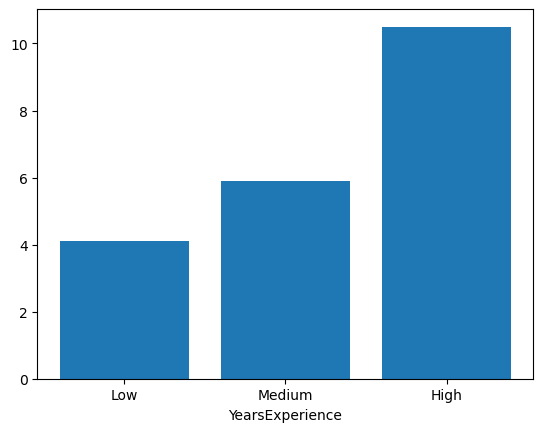

In [46]:
plt.bar(df['Salary_category'],df['YearsExperience'])
plt.xlabel('YearsExperience')

Text(0, 0.5, 'Salary')

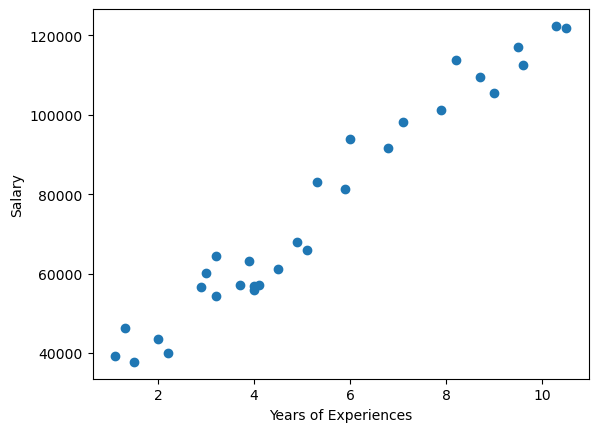

In [59]:
plt.scatter(df.YearsExperience,df.Salary)
plt.xlabel('Years of Experiences')
plt.ylabel('Salary')

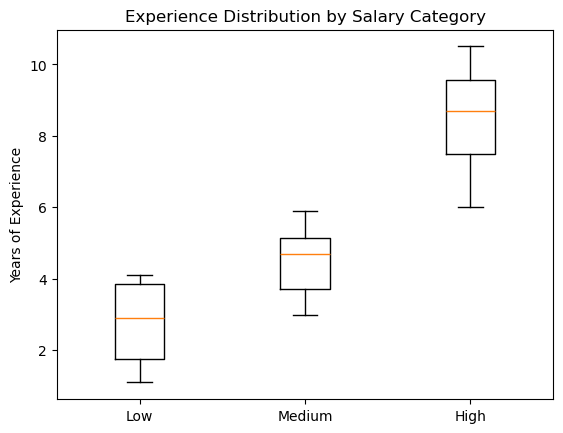

In [56]:
import matplotlib.pyplot as plt
plt.boxplot([df1.YearsExperience, df2.YearsExperience, df3.YearsExperience], 
            labels=['Low', 'Medium', 'High'])
plt.ylabel('Years of Experience')
plt.title('Experience Distribution by Salary Category')
plt.show()


In [51]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.multicomp
mod1=ols(' YearsExperience ~ Salary_category',df).fit()
table = sm.stats.anova_lm(mod1)
print(table)

                   df      sum_sq    mean_sq          F        PR(>F)
Salary_category   2.0  191.528758  95.764379  61.524861  8.794996e-11
Residual         27.0   42.025909   1.556515        NaN           NaN


In [65]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
print(pairwise_tukeyhsd(df.YearsExperience,df.Salary_category))

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
  High    Low  -5.7818    0.0 -7.1008 -4.4628   True
  High Medium  -4.0341    0.0 -5.4714 -2.5967   True
   Low Medium   1.7477 0.0148  0.3104  3.1851   True
----------------------------------------------------


In [62]:
df['YearsExperience'].corr(df['Salary'])

0.9782416184887599

In [63]:
import sklearn,
from sklearn.model_selection import train_test_split

In [64]:
x= df.YearsExperience
y= df.Salary
x_train,x_test, y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=20)
x_train = sm.add_constant(x_train,prepend=False)
mod1 = sm.OLS(y_train,x_train).fit()
print(mod1.summary())
x_test= sm.add_constant(x_test,prepend=False)
y_pred = mod1.predict(x_test)

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     488.2
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.65e-16
Time:                        13:14:59   Log-Likelihood:                -240.44
No. Observations:                  24   AIC:                             484.9
Df Residuals:                      22   BIC:                             487.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
YearsExperience  9492.5208    429.636     